In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import time
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')


In [2]:
data_train=pd.read_csv('titanic_test.csv')
data_train.head()


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [3]:
data_train.shape

(418, 11)

In [4]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    object 
 3   Sex          418 non-null    object 
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    object 
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     object 
 10  Embarked     418 non-null    object 
dtypes: float64(2), int64(4), object(5)
memory usage: 36.1+ KB


In [5]:
data_train.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

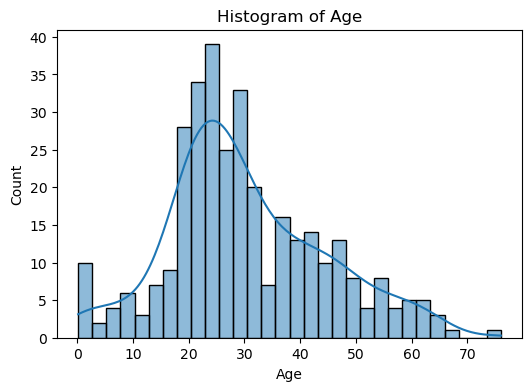

In [6]:
num_cols = ["Age"]

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data_train[col], bins=30, kde=True)
    plt.title(f"Histogram of {col}")
    plt.show()

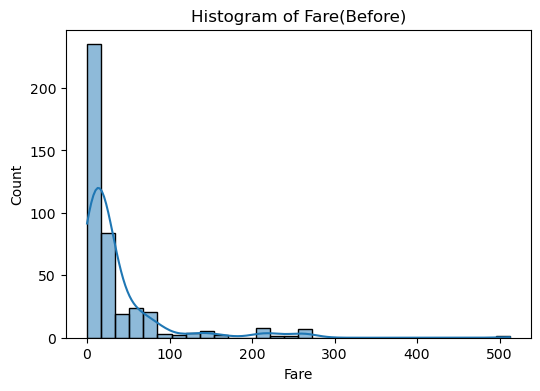

In [7]:
num_cols = ["Fare"]

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data_train[col], bins=30, kde=True)
    plt.title(f"Histogram of {col}(Before)")
    plt.show()

In [8]:
data_filled=data_train.copy()

In [12]:
data_filled['Fare'].fillna(data_filled['Fare'].median(),inplace=True)
data_filled.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
dtype: int64

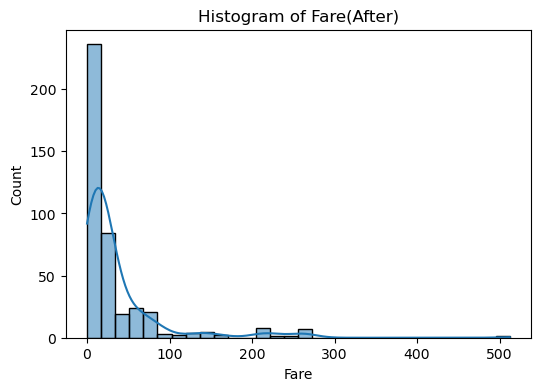

In [13]:
num_cols = ["Fare"]

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data_filled[col], bins=30, kde=True)
    plt.title(f"Histogram of {col}(After)")
    plt.show()

In [14]:
data_filled[data_filled['Fare'].isnull()].index

Index([], dtype='int64')

In [15]:
data_dropped=data_filled.copy()
data_dropped.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
dtype: int64

In [16]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
train_encoded=data_dropped.copy()
print(train_encoded.Embarked.unique())
cols=['Sex','Embarked']
for col in cols:
    train_encoded[col]=le.fit_transform(train_encoded[col])
train_encoded.head()

['Q' 'S' 'C']


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",1,34.5,0,0,330911,7.8292,NaN,1
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",0,47.0,1,0,363272,7.0000,NaN,2
2,894,2,"Myles, Mr. Thomas Francis",1,62.0,0,0,240276,9.6875,NaN,1
3,895,3,"Wirz, Mr. Albert",1,27.0,0,0,315154,8.6625,NaN,2
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",0,22.0,1,1,3101298,12.2875,NaN,2


In [49]:
#using imputer for filling age null values
cols=['Age','Pclass','Sex','Fare','Embarked','SibSp','Parch']
knn=KNNImputer(n_neighbors=5)
df_knn=train_encoded.copy()
#df_knn['Age'].fillna(df_knn['Age'].mode()[0],inplace=True)
df_knn[cols]=knn.fit_transform(df_knn[cols])

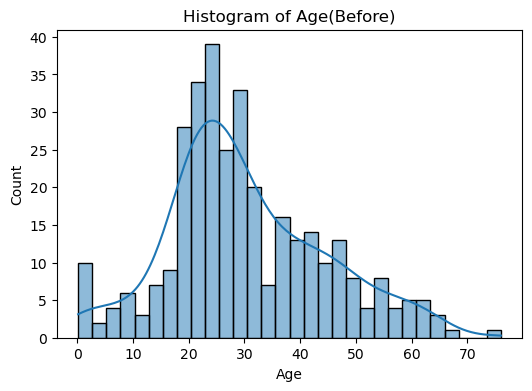

In [19]:
num_cols = ["Age"]

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(data_train[col], bins=30, kde=True)
    plt.title(f"Histogram of {col}(Before)")
    plt.show()

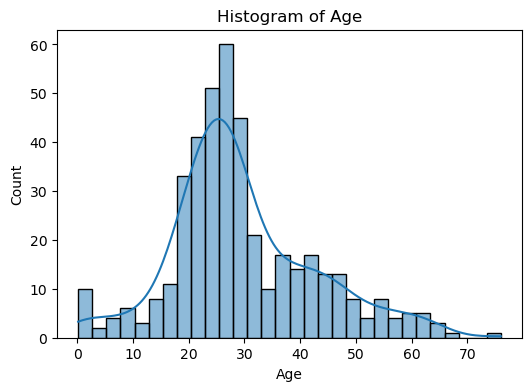

In [50]:
num_cols = ["Age"]

for col in num_cols:
    plt.figure(figsize=(6, 4))
    sns.histplot(df_knn[col], bins=30, kde=True)
    plt.title(f"Histogram of {col}")
    plt.show()

In [51]:
df_knn.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
dtype: int64

In [52]:
df_knn.Embarked.unique()

array([1., 2., 0.])

In [55]:
#Dropping unimportant features
data_dropped=df_knn.drop(columns=['Name', 'Ticket','Cabin','PassengerId','SibSp','Parch','Embarked'])
data_dropped.head()

,Pclass,Sex,Age,Fare
0,3.0,1.0,34.5,7.8292
1,3.0,0.0,47.0,7.0000
2,2.0,1.0,62.0,9.6875
3,3.0,1.0,27.0,8.6625
4,3.0,0.0,22.0,12.2875


In [56]:
data_dropped['Pclass']=data_dropped['Pclass'].astype(int)
data_dropped['Sex']=data_dropped['Sex'].astype(int)

In [57]:
data_dropped

,Pclass,Sex,Age,Fare
0,3,1,34.5,7.8292
1,3,0,47.0,7.0000
2,2,1,62.0,9.6875
3,3,1,27.0,8.6625
4,3,0,22.0,12.2875
...,...,...,...,...
413,3,1,27.6,8.0500
414,1,0,39.0,108.9000
415,3,1,38.5,7.2500
416,3,1,27.6,8.0500


In [61]:
data_dropped.Pclass.value_counts()

Pclass
3    218
1    107
2     93
Name: count, dtype: int64

In [62]:
#StandardScaling
data_n=data_dropped.copy()
nml=StandardScaler()
num_cols=['Age','Fare']
data_n[num_cols]=nml.fit_transform(data_n[num_cols])
data_n

,Pclass,Sex,Age,Fare
0,3,1,0.373291,-0.497413
1,3,0,1.338732,-0.512278
2,2,1,2.497261,-0.464100
3,3,1,-0.205973,-0.482475
4,3,0,-0.592149,-0.417492
...,...,...,...,...
413,3,1,-0.159632,-0.493455
414,1,0,0.720850,1.314435
415,3,1,0.682232,-0.507796
416,3,1,-0.159632,-0.493455


In [66]:
import joblib

# load the trained model
model_c = joblib.load('titanic_model_combined_final.pkl')
print("Model loaded successfully!")


Model loaded successfully!


In [68]:
X_test_final = data_n.copy()
X_test_final

,Pclass,Sex,Age,Fare
0,3,1,0.373291,-0.497413
1,3,0,1.338732,-0.512278
2,2,1,2.497261,-0.464100
3,3,1,-0.205973,-0.482475
4,3,0,-0.592149,-0.417492
...,...,...,...,...
413,3,1,-0.159632,-0.493455
414,1,0,0.720850,1.314435
415,3,1,0.682232,-0.507796
416,3,1,-0.159632,-0.493455


In [69]:
# making predictions using the saved model
predictions = model_c.predict(X_test_final)

print(predictions)


[0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 1 0 0 1 0 0 1 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1
 0 0 0 0 0 0 1 1 0 0 0 1 0 1 0 1 1 0 0 0 0 0 1 0 0 0 1 0 1 1 1 1 1 1 0 0 1
 1 0 0 1 0 1 1 0 0 0 0 0 1 1 0 1 0 0 1 0 1 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 0 1 1 1 0 0 1 0 1 1 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 1 0 0 0
 0 0 1 0 0 0 0 0 1 1 1 1 1 1 1 0 0 0 0 0 1 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 1
 0 1 0 0 0 0 0 1 0 1 0 1 1 0 1 1 1 1 1 0 1 0 0 1 0 0 0 0 1 0 0 1 0 1 0 1 0
 1 0 1 1 0 0 0 0 1 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 1 0 0 0 0 0 1
 0 0 0 1 1 0 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 1 0 0 0 0 0
 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 1 1 0 1 0 0 0 1 1 0
 0 0 1 0 0 0 0 0 0 1 1 0 1 0 0 0 1 1 0 0 0 1 0 1 0 0 0 0 1 1 0 1 0 0 0 1 0
 0 1 0 0 1 1 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0
 1 1 1 0 1 0 0 1 0 0 0]


In [71]:
output = pd.DataFrame({
    'PassengerId': data_train['PassengerId'],
    'Survived': predictions
})
output.to_csv('titanic_submission02_fnl.csv', index=False)
print("Submission file saved!")

Submission file saved!


In [69]:
# making predictions using the saved model
predictions = model.predict(X_test_final)

print(predictions)


[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 0 0 1 1 1 0 1 0 0 0 0 0 1 1 1 0 1
 1 0 0 0 0 0 1 1 0 0 0 1 1 1 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 1 1 1 0 1 1
 1 1 0 1 0 1 0 0 0 0 0 0 1 1 1 1 1 0 1 0 1 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 1 1 0 1
 0 1 0 1 0 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 1 0 1 0 1 0
 1 0 1 1 0 1 0 0 0 1 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 1 0 0 0 0 0 1
 0 0 0 1 1 0 0 1 0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 1 1 0 0 1 0 0 1 1 0 0 0 0
 1 0 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0
 1 0 1 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 1 1 0 1 1 0
 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0
 0 1 1 1 1 1 0 1 0 0 0]


In [ ]:
data_train=pd.read_csv('titanic_test.csv')
data_train.head()
data_fnf=data_train.drop([152])
data_fnf.isnull.sum()

In [70]:
output = pd.DataFrame({
    'PassengerId': data_train['PassengerId'],
    'Survived': predictions
})
output.to_csv('submission.csv', index=False)
print("Submission file saved!")


Submission file saved!


In [71]:
import joblib

# load the trained model
model_comb = joblib.load('titanic_model_combined.pkl')
print("Model loaded successfully!")



Model loaded successfully!


In [73]:
predictions_c = model.predict(X_test_final)

print(predictions_c)

[0 0 0 0 1 0 1 0 1 0 0 0 1 0 1 1 0 0 1 0 0 0 1 1 1 0 1 0 0 0 0 0 1 1 1 0 1
 1 0 0 0 0 0 1 1 0 0 0 1 1 1 0 1 1 0 0 0 0 0 1 0 0 0 1 1 1 1 0 1 1 1 0 1 1
 1 1 0 1 0 1 0 0 0 0 0 0 1 1 1 1 1 0 1 0 1 0 1 0 1 0 1 0 0 0 1 0 0 0 0 0 0
 1 1 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0
 0 0 1 0 0 0 0 0 1 1 0 1 1 0 1 0 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 1 0 1 1 0 1
 0 1 0 1 0 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 0 1 0 1 0 0 0 0 0 1 0 1 0 1 0 1 0
 1 0 1 1 0 1 0 0 0 1 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 0 1 1 1 0 1 0 0 0 0 0 1
 0 0 0 1 1 0 0 1 0 1 0 0 0 1 1 0 1 0 0 0 0 1 0 1 1 1 0 0 1 0 0 1 1 0 0 0 0
 1 0 1 0 0 0 0 0 1 1 1 0 0 0 0 0 0 1 1 1 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1 0
 1 0 1 0 0 0 0 0 0 0 1 0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 1 1 0 1 1 0
 0 1 0 0 1 1 1 0 0 0 0 0 0 1 0 1 0 0 0 0 1 1 0 0 0 1 0 1 0 0 1 0 1 1 0 0 0
 0 1 1 1 1 1 0 1 0 0 0]


In [74]:
output = pd.DataFrame({
    'PassengerId': data_train['PassengerId'],
    'Survived': predictions_c
})
output.to_csv('titanic_submission01.csv', index=False)
print("Submission file saved!")

Submission file saved!


ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()